# Εργασία 3 – Αξιολόγηση Μοντέλων


## "sleep_debt_category" feature prediction

## Import Libraries

In [48]:
import pandas
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## Load Dataset

In [49]:
df = pandas.read_csv("sleep.csv")
df = df.drop(columns=['user_id'])
df

,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt
8496,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt
8497,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit
8498,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt


## Plot Variables

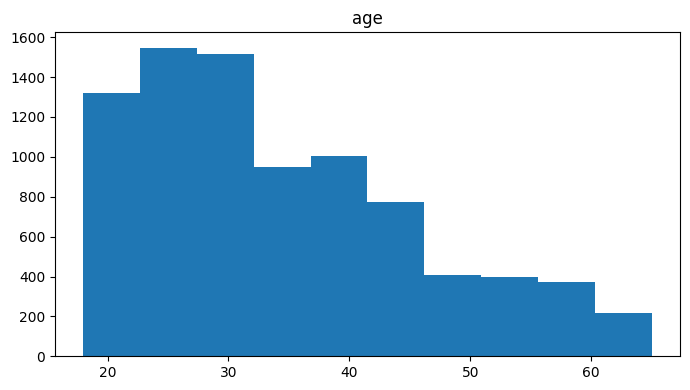

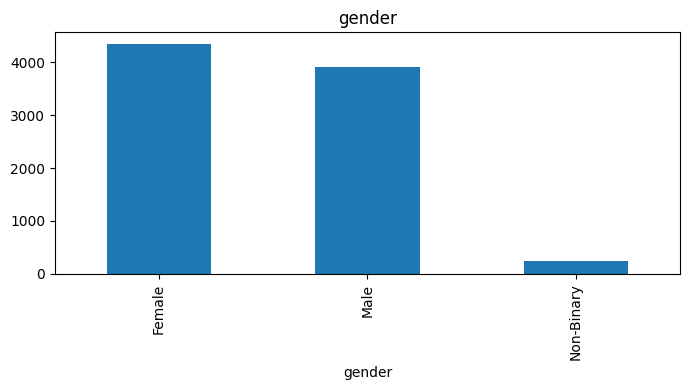

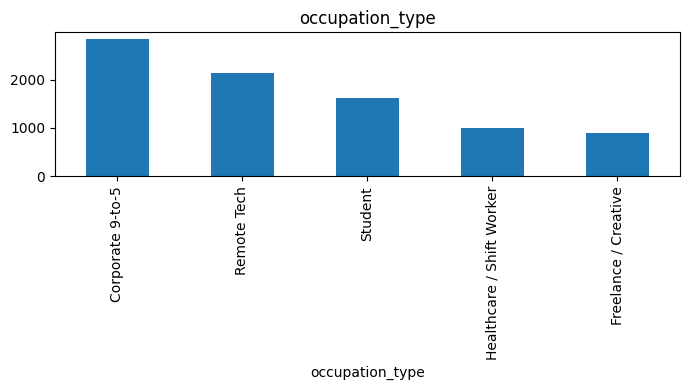

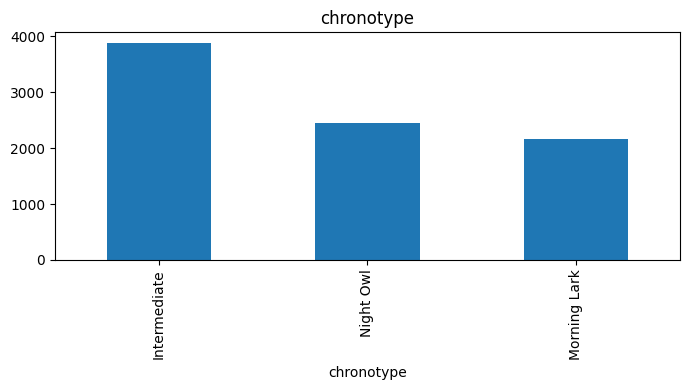

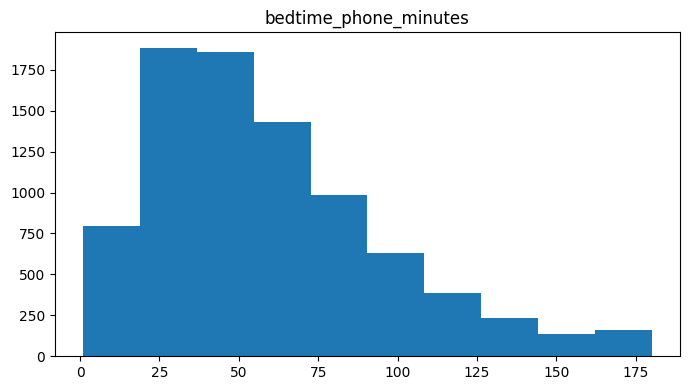

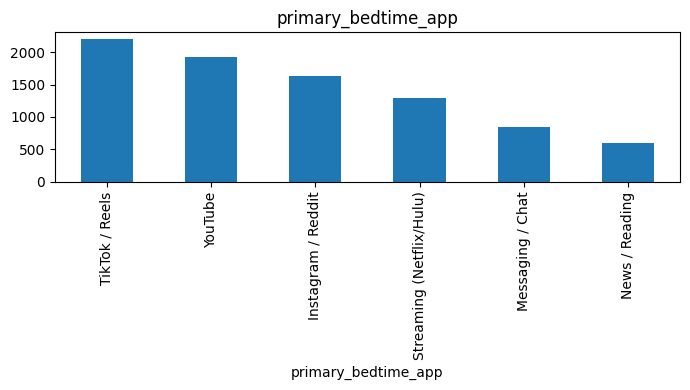

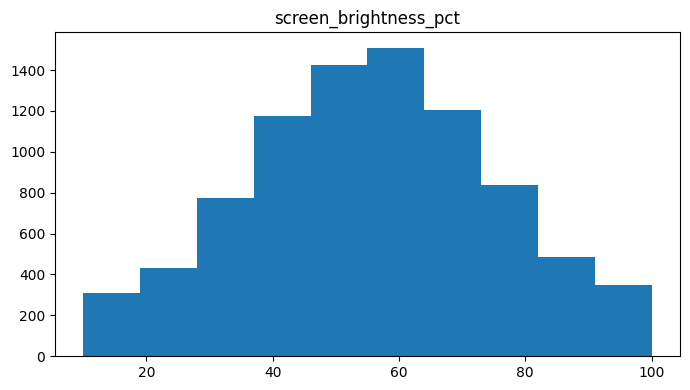

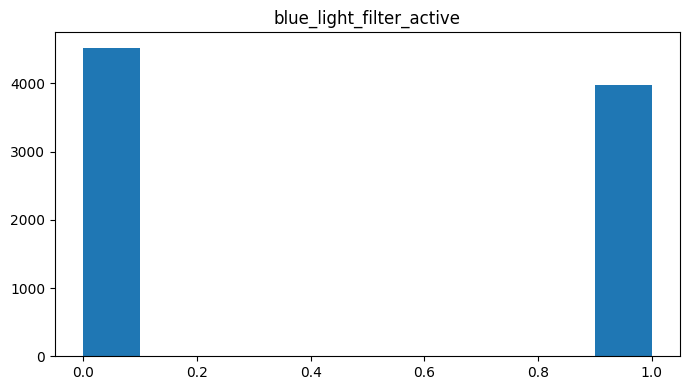

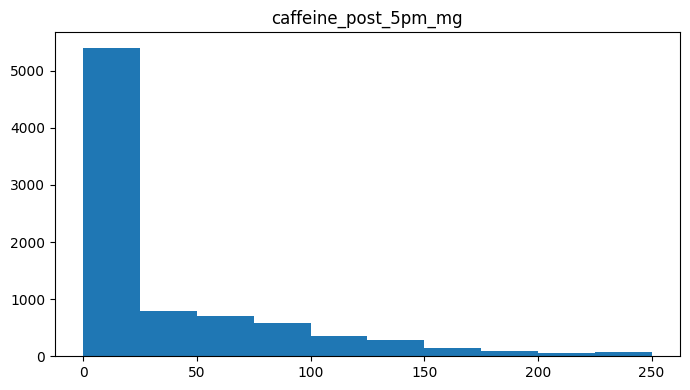

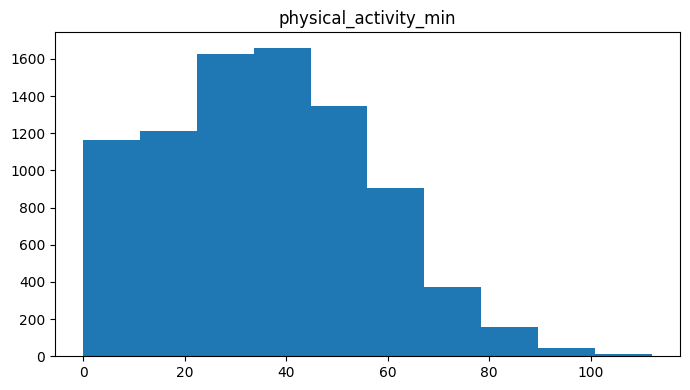

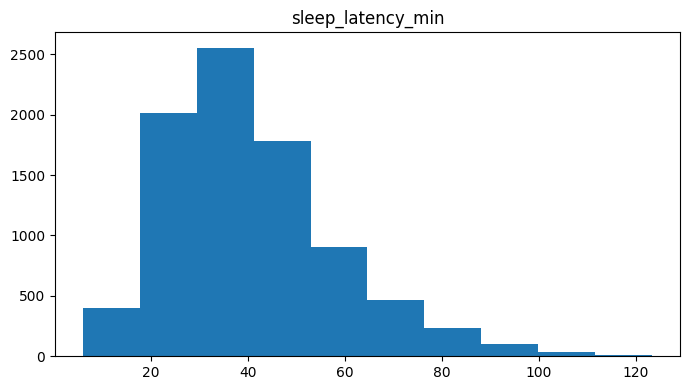

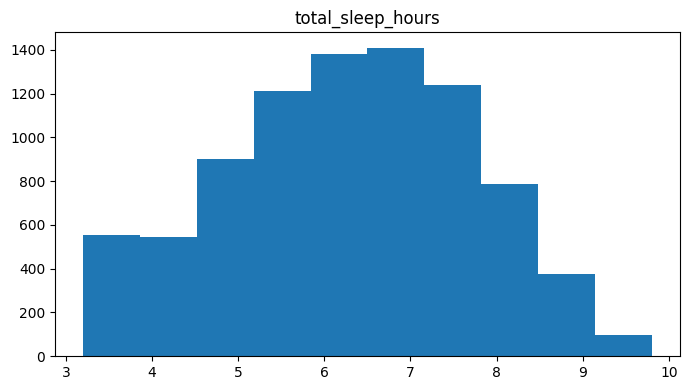

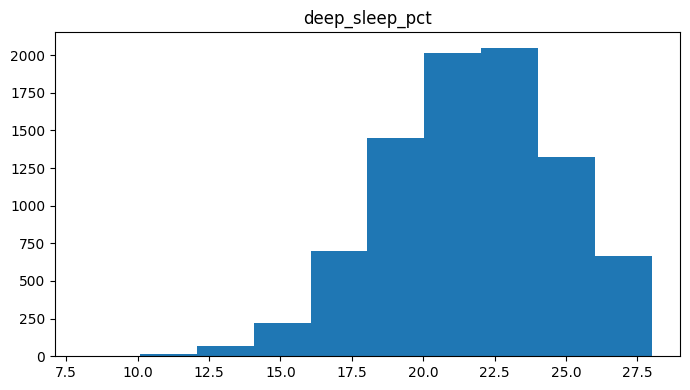

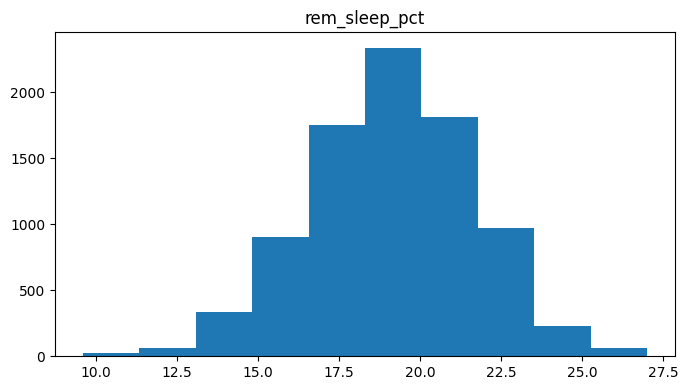

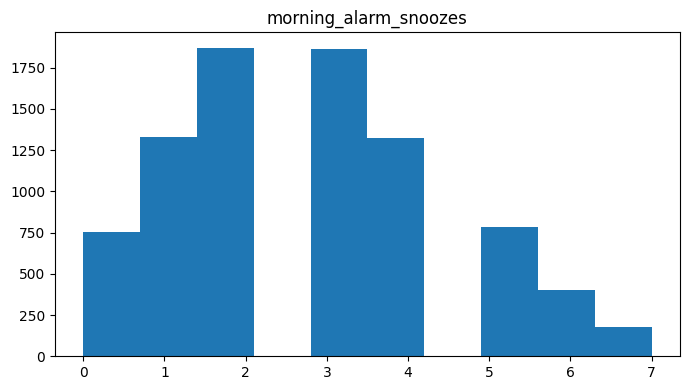

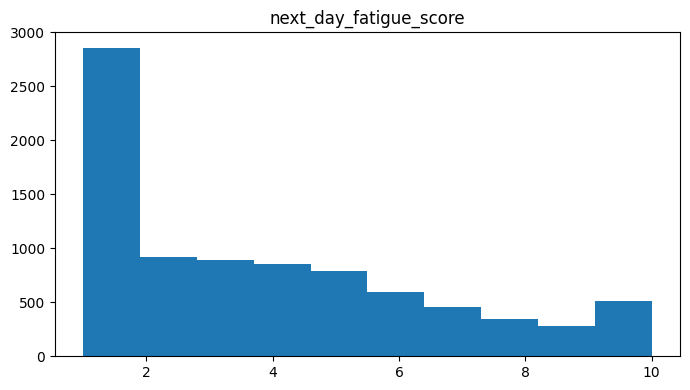

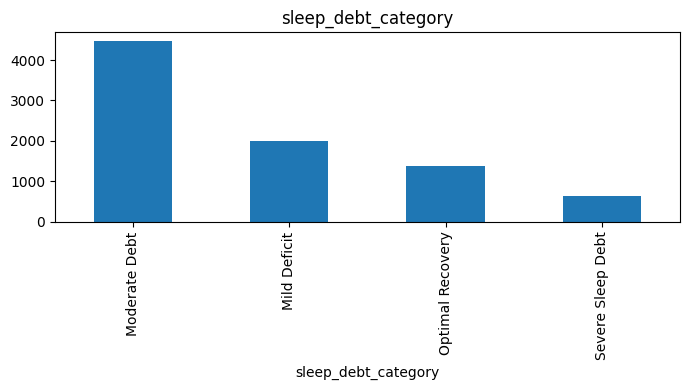

In [50]:
for feature in df.columns:
  plt.figure(figsize=(7, 4))

  if df[feature].dtype == 'object' or df[feature].dtype.name == 'category':
      df[feature].value_counts().plot(kind='bar')
      plt.title(f'{feature}')

  elif pandas.api.types.is_numeric_dtype(df[feature]):
      plt.hist(df[feature])
      plt.title(f'{feature}')

  plt.tight_layout()
  plt.show()

We have a problem regarding imbalanced classes. If we take a look at the target variable (sleep_debt_category), the people with "Severe Sleep debt" are relatively few, less than 15% of the total population. It is not very acute, but it is a significant difference. Without stratification, there is a big possibility that examples from that class may not be taken.

In [51]:
target_column = 'sleep_debt_category'
y = df[target_column]
df = df.drop(columns=target_column)

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
category_cols = df.select_dtypes(include=['object', 'category']).columns

## Remove feature "next_day_fatigue"

In [52]:
df = df.drop(columns=['next_day_fatigue_score'])

## Encoding

In [53]:
df = pandas.get_dummies(df, drop_first=True, dtype=int)
y = y.map({'Moderate Debt': 0, 'Mild Deficit': 1, 'Optimal Recovery': 2, 'Severe Sleep Debt': 3})
df

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,occupation_type_Healthcare / Shift Worker,occupation_type_Remote Tech,occupation_type_Student,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,29,179,54,1,0,21,84.4,3.20,23.5,22.2,...,1,0,0,0,0,0,0,0,0,0
1,58,163,76,1,92,72,86.7,4.06,18.0,21.5,...,0,0,1,0,0,0,0,0,0,1
2,41,100,59,0,45,23,70.5,3.20,18.1,20.5,...,1,0,0,0,1,0,0,0,1,0
3,36,34,52,0,97,49,38.1,6.99,21.6,22.4,...,0,1,0,0,0,0,0,0,0,1
4,23,27,82,1,0,38,32.3,4.58,24.1,22.8,...,1,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,61,18,61,1,60,74,21.0,5.57,26.5,18.1,...,0,1,0,0,1,0,0,1,0,0
8496,64,138,58,1,0,58,84.3,3.99,20.4,19.4,...,0,0,1,0,1,0,0,0,1,0
8497,34,56,56,0,94,33,40.6,7.58,17.4,20.7,...,0,0,0,0,0,0,0,1,0,0
8498,23,165,72,0,0,52,123.3,3.20,14.2,15.8,...,1,0,0,0,1,0,0,0,1,0


## Convert DataFrame to Numpy arrays

In [54]:
x = df.to_numpy()
y = y.to_numpy()
x.shape, y.shape

((8500, 24), (8500,))

## Split Dataset to Train-Validation-Test

In [55]:
seed = 0
valid_size = 0.2
test_size = 0.1

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.3, train_size=0.7, random_state=seed, stratify=y)
x_valid, x_test, y_valid, y_test = train_test_split(x_temp, y_temp, test_size=0.33, train_size=0.67, random_state=seed, stratify=y_temp)

## Normalisation

In [56]:
scaler = StandardScaler()

scaler.fit(x_train)
x_train = scaler.transform(x_train)
x_valid = scaler.transform(x_valid)

## K- NN

### Import Libraries

In [57]:
from math import sqrt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score

### Initialise Values

In [58]:
N = x_train.shape[0]
K = [3, 5, 15, 50, int(sqrt(N))]
weights = ['uniform', 'distance']

### Finding Best values for Parametres

In [59]:
for weight in weights:
  print(f"{weight} K-NN algorithm")
  for k in K:
    knn = KNeighborsClassifier(n_neighbors=k, weights=weight, p=2, metric='minkowski')

    knn.fit(x_train, y_train)

    y_pred = knn.predict(x_valid)

    accuracy = accuracy_score(y_valid, y_pred)
    accuracy_percentage = round(accuracy*100, 2)

    precision = precision_score(y_valid, y_pred, average='weighted')
    precision_percentage = round(precision*100, 2)

    recall = recall_score(y_valid, y_pred, average='weighted')
    recall_percentage = round(recall*100, 2)

    f1 = f1_score(y_valid, y_pred, average='weighted')
    f1_percentage = round(f1*100, 2)

    balanced_accuracy = balanced_accuracy_score(y_valid, y_pred)
    balanced_accuracy_percentage = round(balanced_accuracy*100, 2)

    print(f"Validation: K = {k:4d} | Accuracy: {accuracy_percentage}%, Precision: {precision_percentage}%, Recall: {recall_percentage}%, F1: {f1_percentage}%, Balanced_Acc: {balanced_accuracy_percentage}%")

  print()
  print("-------------------")
  print()



uniform K-NN algorithm
Validation: K =    3 | Accuracy: 69.15%, Precision: 68.92%, Recall: 69.15%, F1: 68.7%, Balanced_Acc: 61.68%
Validation: K =    5 | Accuracy: 71.49%, Precision: 71.95%, Recall: 71.49%, F1: 71.19%, Balanced_Acc: 63.11%
Validation: K =   15 | Accuracy: 74.06%, Precision: 74.53%, Recall: 74.06%, F1: 73.49%, Balanced_Acc: 63.93%
Validation: K =   50 | Accuracy: 74.65%, Precision: 75.42%, Recall: 74.65%, F1: 73.4%, Balanced_Acc: 60.94%
Validation: K =   77 | Accuracy: 74.24%, Precision: 75.24%, Recall: 74.24%, F1: 72.65%, Balanced_Acc: 58.96%

-------------------

distance K-NN algorithm
Validation: K =    3 | Accuracy: 69.5%, Precision: 69.82%, Recall: 69.5%, F1: 69.52%, Balanced_Acc: 63.06%
Validation: K =    5 | Accuracy: 71.08%, Precision: 71.45%, Recall: 71.08%, F1: 71.0%, Balanced_Acc: 63.62%
Validation: K =   15 | Accuracy: 74.0%, Precision: 74.46%, Recall: 74.0%, F1: 73.6%, Balanced_Acc: 64.58%
Validation: K =   50 | Accuracy: 75.23%, Precision: 75.97%, Recall:

We will choose:  k = 50 and the weighted version

We are between k = 15 and k = 50. As we can see:


*   k = 15 has a better balanced accuracy value
*   k = 50 has a better F1 score value

Given the fact that our application has a medical interest, we want to be true and sure about the most severe cases that are the most rare too. So, we will choses the value with the highest F1 score.  

### Evaluation in Test Set

#### Uniting Train and Valid sets

In [60]:
x_train = x_train.tolist()
x_valid = x_valid.tolist()
x_train.extend(x_valid)
x_train = np.array(x_train)

y_train = y_train.tolist()
y_valid = y_valid.tolist()
y_train.extend(y_valid)
y_train = np.array(y_train)

#### Update Scaler

In [61]:
x_test = scaler.transform(x_test)

#### Running K-NN for k = 50 and weighted version

In [62]:
knn = KNeighborsClassifier(n_neighbors=50, weights='distance', p=2, metric='minkowski')

knn.fit(x_train, y_train)

y_pred = knn.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

precision = precision_score(y_test, y_pred, average='weighted')
precision_percentage = round(precision*100, 2)

recall = recall_score(y_test, y_pred, average='weighted')
recall_percentage = round(recall*100, 2)

f1 = f1_score(y_test, y_pred, average='weighted')
f1_percentage = round(f1*100, 2)

print(f"Test: Accuracy: {accuracy_percentage}%, Precision: {precision_percentage}%, Recall: {recall_percentage}%, F1: {f1_percentage}%")

Test: Accuracy: 75.3%, Precision: 76.7%, Recall: 75.3%, F1: 73.78%


### Interprentation of Results

In general, we see steady and robust results. The close values between validations and tests evaluations confirm that the model successfully generalized to new data without overfitting

## Cross Validation

### Import Libaries

In [63]:
from sklearn import svm
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
import scipy.stats as stats
from sklearn.metrics import accuracy_score

### Split Data to Train - Test

In [64]:
seed = 0
x.shape, y.shape

((8500, 24), (8500,))

In [65]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, train_size=0.7, random_state=seed, stratify=y)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5950, 24), (2550, 24), (5950,), (2550,))

### 5-Fold CV

In [72]:
k_values = [3, 5, 15, 50]
weight_options = ['uniform', 'distance']

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

best_score = -1
best_params = None
best_metrics_per_fold = None

results = []

for k in k_values:
    for weight in weight_options:

        fold_acc = []
        fold_prec = []
        fold_rec = []
        fold_f1 = []
        fold_bal_acc = []

        for train_index, val_index in kf.split(X_train, y_train):
            X_tr, X_val = X_train[train_index], X_train[val_index]
            y_tr, y_val = y_train[train_index], y_train[val_index]

            scaler = StandardScaler()
            X_tr_scaled = scaler.fit_transform(X_tr)
            X_val_scaled = scaler.transform(X_val)

            knn = KNeighborsClassifier(n_neighbors=k, weights=weight, p=2, metric='minkowski')
            knn.fit(X_tr_scaled, y_tr)
            y_pred = knn.predict(X_val_scaled)

            fold_acc.append(accuracy_score(y_val, y_pred))
            fold_prec.append(precision_score(y_val, y_pred, average='weighted', zero_division=0))
            fold_rec.append(recall_score(y_val, y_pred, average='weighted', zero_division=0))
            fold_f1.append(f1_score(y_val, y_pred, average='weighted', zero_division=0))
            fold_bal_acc.append(balanced_accuracy_score(y_val, y_pred))

        mean_acc = np.mean(fold_acc)
        mean_prec = np.mean(fold_prec)
        mean_rec = np.mean(fold_rec)
        mean_f1 = np.mean(fold_f1)
        mean_bal_acc = np.mean(fold_bal_acc)

        results.append({
            'k': k, 'weight': weight,
            'Accuracy': mean_acc, 'Precision': mean_prec,
            'Recall': mean_rec, 'F1': mean_f1, 'Balanced Acc': mean_bal_acc,
            'raw_scores': {'Accuracy': fold_acc, 'Precision': fold_prec, 'Recall': fold_rec, 'F1': fold_f1, 'Balanced Acc': fold_bal_acc}
        })

        # I choose based on F1-score due to imbalanced class problem
        if mean_f1 > best_score:
            best_score = mean_f1
            best_params = (k, weight)
            best_metrics_per_fold = results[-1]['raw_scores']

print(f"Best: k={best_params[0]}, weights={best_params[1]}")

print("\n--- 95% Confidence Intervals ---")
n_folds = 5
confidence = 0.95

for metric_name, scores in best_metrics_per_fold.items():
    mean = np.mean(scores)
    sem = stats.sem(scores)
    h = sem * stats.t.ppf((1 + confidence) / 2, n_folds - 1)
    print(f"{metric_name}: {mean:.4f} ± {h:.4f}  (CI: [{mean - h:.4f}, {mean + h:.4f}])")




Best: k=15, weights=distance

--- 95% Confidence Intervals ---
Accuracy: 0.7513 ± 0.0172  (CI: [0.7341, 0.7685])
Precision: 0.7573 ± 0.0221  (CI: [0.7352, 0.7794])
Recall: 0.7513 ± 0.0172  (CI: [0.7341, 0.7685])
F1: 0.7427 ± 0.0190  (CI: [0.7237, 0.7618])
Balanced Acc: 0.6339 ± 0.0185  (CI: [0.6154, 0.6523])


## Final Evaluation in Test Set

In [76]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

best_knn = KNeighborsClassifier(n_neighbors=15, weights='distance', p=2, metric='minkowski')
best_knn.fit(X_train, y_train)

y_pred = best_knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

precision = precision_score(y_test, y_pred, average='weighted')
precision_percentage = round(precision*100, 2)

recall = recall_score(y_test, y_pred, average='weighted')
recall_percentage = round(recall*100, 2)

f1 = f1_score(y_test, y_pred, average='weighted')
f1_percentage = round(f1*100, 2)

balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
balanced_accuracy_percentage = round(balanced_accuracy*100, 2)

print(f"Test: Accuracy: {accuracy_percentage}%, Precision: {precision_percentage}%, Recall: {recall_percentage}%, F1: {f1_percentage}%, Balanced_accuracy: {balanced_accuracy_percentage}%")



Test: Accuracy: 73.76%, Precision: 74.31%, Recall: 73.76%, F1: 73.27%, Balanced_accuracy: 63.86%


We can see that the results of all metrics are inside their respective CI

## Nested Cross Validation

*   Outer loop: 3
*   Inner Loop: 5




### Print Data Info

In [77]:
seed = 0
x.shape, y.shape

((8500, 24), (8500,))

### Training and Evaluation

In [83]:
outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

k_values = [3, 5, 15, 50]
weight_options = ['uniform', 'distance']

outer_results = []

for outer_fold, (train_index, test_index) in enumerate(outer_cv.split(x, y)):

    X_train_outer, X_test_outer = x[train_index], x[test_index]
    y_train_outer, y_test_outer = y[train_index], y[test_index]

    best_inner_score = -1
    best_params = None

    for k in k_values:
        for weight in weight_options:
            inner_scores = []

            for inner_train_idx, inner_val_idx in inner_cv.split(X_train_outer, y_train_outer):
                X_tr, X_val = X_train_outer[inner_train_idx], X_train_outer[inner_val_idx]
                y_tr, y_val = y_train_outer[inner_train_idx], y_train_outer[inner_val_idx]

                scaler = StandardScaler()
                X_tr_scaled = scaler.fit_transform(X_tr)
                X_val_scaled = scaler.transform(X_val)

                knn = KNeighborsClassifier(n_neighbors=k, weights=weight)
                knn.fit(X_tr_scaled, y_tr)
                y_pred = knn.predict(X_val_scaled)

                inner_scores.append(f1_score(y_val, y_pred, average='weighted', zero_division=0))

            mean_inner_score = np.mean(inner_scores)

            if mean_inner_score > best_inner_score:
                best_inner_score = mean_inner_score
                best_params = (k, weight)

    scaler = StandardScaler()
    X_train_outer_scaled = scaler.fit_transform(X_train_outer)
    X_test_outer_scaled = scaler.transform(X_test_outer)

    best_knn = KNeighborsClassifier(n_neighbors=best_params[0], weights=best_params[1])
    best_knn.fit(X_train_outer_scaled, y_train_outer)
    y_test_pred = best_knn.predict(X_test_outer_scaled)

    outer_results.append({
        'fold': outer_fold + 1,
        'best_params': best_params,
        'Accuracy': accuracy_score(y_test_outer, y_test_pred),
        'Precision': precision_score(y_test_outer, y_test_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test_outer, y_test_pred, average='weighted', zero_division=0),
        'F1': f1_score(y_test_outer, y_test_pred, average='weighted', zero_division=0),
        'Balanced Acc': balanced_accuracy_score(y_test_outer, y_test_pred)
    })

print("Final Results for Nested CV")
print()
print
for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'Balanced Acc']:
    scores = [res[metric] for res in outer_results]
    print(f"{metric}: [{np.mean(scores - np.std(scores)):.4f}, {np.mean(scores + np.std(scores)):.4f}]")

Final Results for Nested CV

Accuracy: [0.7437, 0.7452]
Precision: [0.7494, 0.7526]
Recall: [0.7437, 0.7452]
F1: [0.7370, 0.7386]
Balanced Acc: [0.6271, 0.6394]


Here, I did the nested cross validation in the whole data set. I didn't keep a test set to check if the intervals are ok. The concept is the same with the standard K-Fold CV